# SC4002 Group Assignment: joint intent detection and slot filling on MASSIVE (en-US)

Every system here reads an English assistant request (`utt`) and, in one joint model, outputs one of 60 intents and
the set of `[slot type : slot span]` pairs (55 slot types).

## Summary

| | Stage 1: baseline | Stage 2: AI-collaborative improvement |
|---|---|---|
| Model family | Joint **iterated dilated CNN** (ID-CNN) + CRF | Ensemble of joint **gated dilated CNNs** + constrained CRF |
| Word input | GloVe-initialised, fine-tuned word embeddings + char-CNN | Clitic-aware sub-tokens; frozen GloVe and fastText, small trainable embedding, char-CNN, hashed char n-grams |
| Intent head | mean + max pooling, MLP | same, plus a scenario head combined hierarchically |
| Slot head | linear emissions, CRF | intent-aware emissions, CRF with hard BIO constraints |
| Training | AdamW, plateau schedule, early stopping on dev | AdamW, warmup + cosine schedule, label smoothing, weight averaging (SWA) over late epochs |

**Why a convolutional family?** Other members of the group built BiLSTM and Transformer systems. A dilated CNN
reads the whole utterance in parallel: three stacked width-3 convolutions with dilation 1, 2 and 4 see 15 tokens, and
iterating the block twice sees 29, more than 95% of MASSIVE utterances (95th percentile: 13 tokens). With no
recurrence, all positions are computed in parallel, so the models train on a laptop CPU (per-epoch times are printed
in Sections 6.4 and 7.4); that is what kept a multi-member Stage 2 ensemble and the ablations affordable.

All scores are printed by the cells that compute them (Sections 6.6, 7.6 and 8). Nothing in this notebook is typed
by hand.

## Where to find each requirement

| Requirement (brief, Section 5) | Location |
|---|---|
| Load and verify the dataset; assert 11,514 / 2,033 / 2,974 | Section 2 |
| Preprocessing into model inputs and labels | Sections 2.1, 4, 6.1, 7.2 |
| Shared evaluation functions (intent accuracy, slot micro-F1) | Section 3 |
| Stage 1 model: architecture, inputs, outputs, loss, optimiser; parameter count within 20M | Sections 6, 6.3 |
| Stage 1 training logs, per-epoch losses and validation scores, elapsed time, learning curves; best checkpoint | Sections 6.4, 6.5 |
| Stage 1 final evaluation: reload, validation check, test scores | Section 6.6 |
| Stage 2 diagnosis of Stage 1 weaknesses (validation split) | Section 7.1 |
| Stage 2 model, parameter count within 20M | Sections 7.2, 7.3 |
| Stage 2 training logs, learning curves, best checkpoint | Sections 7.4, 7.5 |
| Stage 2 final evaluation: reload, validation check, test scores | Section 7.6 |
| Results table in the report format | Section 8 |
| Error analysis of the Stage 2 system | Section 9 |

Hyperparameter search for Stage 1 is in `stage1_tuning.ipynb`, and the Stage 2 ablations are in
`stage2_experiments.ipynb`. Both use the validation split only.

## 1. Setup

Everything runs from the repository root. Missing data and word vectors are downloaded on first use into
`data/` and `embeddings/` (both git-ignored). On a machine with CUDA the GPU is used; otherwise the CPU.

In [1]:
import os, re, json, time, math, random, copy, zlib, tarfile, zipfile, urllib.request
from collections import Counter, defaultdict

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

DATA_DIR, EMB_DIR, CKPT_DIR, FIG_DIR = "data", "embeddings", "checkpoints", "figures"
for d in (DATA_DIR, EMB_DIR, CKPT_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

MASSIVE_URL = "https://amazon-massive-nlu-dataset.s3.amazonaws.com/amazon-massive-dataset-1.0.tar.gz"
MASSIVE_PATH = os.path.join(DATA_DIR, "1.0", "data", "en-US.jsonl")
GLOVE_PATH = os.path.join(EMB_DIR, "glove.6B.300d.txt")
GLOVE_URLS = ["https://nlp.stanford.edu/data/glove.6B.zip",
              "https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip"]
FASTTEXT_PATH = os.path.join(EMB_DIR, "crawl-300d-2M.vec")
FASTTEXT_URL = "https://dl.fbaipublicfiles.com/fasttext/vectors-english/crawl-300d-2M.vec.zip"


def pick_device():
    # On an Apple M2 the CPU was faster than the MPS GPU for these small models (timed: 25 s vs 50+ s per epoch),
    # so MPS is not used. On a machine with CUDA the GPU is used.
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


DEVICE = pick_device()
if "TORCH_THREADS" in os.environ:
    torch.set_num_threads(int(os.environ["TORCH_THREADS"]))


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def download(url, dest):
    print(f"Downloading {url}")
    urllib.request.urlretrieve(url, dest)


def ensure_massive():
    if not os.path.exists(MASSIVE_PATH):
        archive = os.path.join(DATA_DIR, "amazon-massive-dataset-1.0.tar.gz")
        download(MASSIVE_URL, archive)
        with tarfile.open(archive) as tar:
            tar.extract("1.0/data/en-US.jsonl", DATA_DIR)
        os.remove(archive)
    return MASSIVE_PATH


def ensure_glove():
    if not os.path.exists(GLOVE_PATH):
        archive = os.path.join(EMB_DIR, "glove.6B.zip")
        for url in GLOVE_URLS:
            try:
                download(url, archive)
                break
            except Exception as err:
                print(f"  failed ({err})")
        with zipfile.ZipFile(archive) as z:
            z.extract("glove.6B.300d.txt", EMB_DIR)
        os.remove(archive)
    return GLOVE_PATH


def ensure_fasttext():
    if not os.path.exists(FASTTEXT_PATH):
        archive = FASTTEXT_PATH + ".zip"
        download(FASTTEXT_URL, archive)
        with zipfile.ZipFile(archive) as z:
            z.extract("crawl-300d-2M.vec", EMB_DIR)
        os.remove(archive)
    return FASTTEXT_PATH


print("torch", torch.__version__, "| device:", DEVICE)

torch 2.12.0 | device: cpu


## 2. Load and verify the dataset

MASSIVE 1.0, `1.0/data/en-US.jsonl`, split with the existing `partition` field. The only model input is `utt`;
labels come from `intent` and `annot_utt`. Nothing is re-split, added or removed.

In [2]:
def load_massive(path):
    with open(path, encoding="utf-8") as f:
        records = [json.loads(line) for line in f if line.strip()]
    splits = {name: [r for r in records if r["partition"] == name] for name in ("train", "dev", "test")}
    return records, splits


records, raw = load_massive(ensure_massive())
print(f"Total labelled examples: {len(records):,}")
for name in ("train", "dev", "test"):
    print(f"  {name:<5} {len(raw[name]):>6,}")
assert len(records) == 16_521
assert len(raw["train"]) == 11_514 and len(raw["dev"]) == 2_033 and len(raw["test"]) == 2_974
print("Split sizes verified against the brief: 11,514 / 2,033 / 2,974.")
print("Example record:", {k: raw["train"][0][k] for k in ("utt", "intent", "annot_utt")})

Total labelled examples: 16,521
  train 11,514
  dev    2,033
  test   2,974
Split sizes verified against the brief: 11,514 / 2,033 / 2,974.
Example record: {'utt': 'wake me up at nine am on friday', 'intent': 'alarm_set', 'annot_utt': 'wake me up at [time : nine am] on [date : friday]'}


### 2.1 Labels: from `annot_utt` to BIO tags

`annot_utt` marks each slot as `[type : words]`. We turn it into one tag per whitespace token: `B-type` on the first
word of a slot, `I-type` on the following words, `O` elsewhere. The parser asserts that the tokens it recovers are
exactly `utt.split()`, so labels and inputs can never drift apart. The gold set of `(slot type, span text)` pairs is
read straight from `annot_utt` and is what every model is scored against.

In [3]:
SLOT_RE = re.compile(r"\[\s*([^\[\]:]+?)\s*:\s*([^\[\]]*?)\s*\]")


def parse_annot(annot_utt):
    """'wake me up at [time : five am]' -> tokens, BIO tags, gold set of (slot_type, span_text)."""
    tokens, tags, spans, pos = [], [], set(), 0
    for m in SLOT_RE.finditer(annot_utt):
        outside = annot_utt[pos:m.start()].split()
        tokens += outside
        tags += ["O"] * len(outside)
        slot_type, words = m.group(1).strip(), m.group(2).split()
        tokens += words
        tags += [f"B-{slot_type}"] + [f"I-{slot_type}"] * (len(words) - 1)
        spans.add((slot_type, " ".join(words)))
        pos = m.end()
    outside = annot_utt[pos:].split()
    tokens += outside
    tags += ["O"] * len(outside)
    return tokens, tags, spans


def to_example(r):
    tokens, tags, spans = parse_annot(r["annot_utt"])
    assert tokens == r["utt"].split(), f"annot_utt and utt disagree for id {r['id']}"
    return {"id": r["id"], "utt": r["utt"], "tokens": tokens, "tags": tags, "gold_spans": spans,
            "intent": r["intent"], "scenario": r["intent"].split("_", 1)[0]}


data = {name: [to_example(r) for r in raw[name]] for name in ("train", "dev", "test")}
ex = data["train"][0]
print(ex["tokens"], ex["tags"], ex["gold_spans"], ex["intent"], sep="\n")

lengths = [len(e["tokens"]) for e in data["train"]]
print(f"train utterance length: mean {np.mean(lengths):.1f}, 95th pct {np.percentile(lengths, 95):.0f}, max {max(lengths)}")

['wake', 'me', 'up', 'at', 'nine', 'am', 'on', 'friday']
['O', 'O', 'O', 'O', 'B-time', 'I-time', 'O', 'B-date']
{('time', 'nine am'), ('date', 'friday')}
alarm_set
train utterance length: mean 6.9, 95th pct 13, max 35


## 3. Shared evaluation functions

One scorer is used for every experiment in this repository:

* **Intent accuracy** = 100 x correct intents / utterances.
* **Slot micro-F1**: for each utterance, compare the *set* of predicted `(slot type, span text)` pairs with the gold
  set. A true positive needs both the type and the exact span. TP, FP and FN are pooled over all utterances, and
  F1 = 100 x 2TP / (2TP + FP + FN).
* Turning tags into spans is part of the model, not the scorer. An `I-x` that does not continue an `x` span starts a
  new span (the usual CoNLL convention), so an invalid tag sequence is still scored, never silently repaired.

The checks below test hand-built cases, and confirm that gold tags reproduce 100.00 on every split.

In [4]:
def tags_to_spans(tokens, tags):
    """BIO tags -> set of (slot_type, span_text). An I-x that does not continue an x span starts a new span."""
    spans, cur_type, cur_words = set(), None, []
    for tok, tag in zip(tokens, tags):
        if tag == "O":
            if cur_type:
                spans.add((cur_type, " ".join(cur_words)))
            cur_type, cur_words = None, []
        elif tag.startswith("B-") or tag[2:] != cur_type:
            if cur_type:
                spans.add((cur_type, " ".join(cur_words)))
            cur_type, cur_words = tag[2:], [tok]
        else:
            cur_words.append(tok)
    if cur_type:
        spans.add((cur_type, " ".join(cur_words)))
    return spans


def intent_accuracy(pred_intents, gold_intents):
    return 100.0 * sum(p == g for p, g in zip(pred_intents, gold_intents)) / len(gold_intents)


def slot_counts(pred_span_sets, gold_span_sets):
    tp = fp = fn = 0
    for pred, gold in zip(pred_span_sets, gold_span_sets):
        tp += len(pred & gold)
        fp += len(pred - gold)
        fn += len(gold - pred)
    return tp, fp, fn


def slot_micro_f1(pred_span_sets, gold_span_sets):
    tp, fp, fn = slot_counts(pred_span_sets, gold_span_sets)
    return 100.0 * 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 100.0


def score(pred_intents, pred_spans, examples):
    """The one scoring rule used for every experiment in this project."""
    gold_intents = [e["intent"] for e in examples]
    gold_spans = [e["gold_spans"] for e in examples]
    tp, fp, fn = slot_counts(pred_spans, gold_spans)
    acc = intent_accuracy(pred_intents, gold_intents)
    f1 = slot_micro_f1(pred_spans, gold_spans)
    return {"intent_acc": acc, "slot_f1": f1, "combined": (acc + f1) / 2,
            "intent_correct": sum(p == g for p, g in zip(pred_intents, gold_intents)), "tp": tp, "fp": fp, "fn": fn}


# Unit tests on hand-built cases
toks = "wake me up at five am this week".split()
assert tags_to_spans(toks, ["O", "O", "O", "O", "B-time", "I-time", "B-date", "I-date"]) == {("time", "five am"), ("date", "this week")}
assert tags_to_spans(toks, ["O", "O", "O", "O", "I-time", "I-time", "O", "O"]) == {("time", "five am")}
assert tags_to_spans(toks, ["O", "O", "O", "O", "B-time", "I-date", "O", "O"]) == {("time", "five"), ("date", "am")}
assert slot_counts([{("a", "x"), ("b", "y")}], [{("a", "x"), ("b", "z")}]) == (1, 1, 1)
assert abs(slot_micro_f1([{("a", "x"), ("b", "y")}], [{("a", "x"), ("b", "z")}]) - 50.0) < 1e-9
assert intent_accuracy(["a", "b", "c", "d"], ["a", "b", "x", "d"]) == 75.0
# Gold tags must reproduce the gold span sets exactly on every split
for name, exs in data.items():
    s = score([e["intent"] for e in exs], [tags_to_spans(e["tokens"], e["tags"]) for e in exs], exs)
    assert s["intent_acc"] == 100.0 and s["slot_f1"] == 100.0, name
    print(f"{name}: gold round trip -> intent {s['intent_acc']:.2f}, slot F1 {s['slot_f1']:.2f}, gold slots {s['tp']:,}")

train: gold round trip -> intent 100.00, slot F1 100.00, gold slots 11,340
dev: gold round trip -> intent 100.00, slot F1 100.00, gold slots 2,011
test: gold round trip -> intent 100.00, slot F1 100.00, gold slots 2,815


**Test lock.** The test split can only be scored after a stage's checkpoint is frozen. `check_split_allowed` raises
an error otherwise, which makes accidental test-set tuning impossible rather than just discouraged.

In [5]:
TEST_UNLOCKED = {"stage1": False, "stage2": False}


def check_split_allowed(split, stage):
    if split == "test" and not TEST_UNLOCKED[stage]:
        raise RuntimeError(f"Test split is locked for {stage}: freeze the checkpoint first.")

## 4. Vocabularies, word vectors and batching

Intent, scenario, tag, word and character vocabularies are built from the **training split only**. Dev and test words
never seen in training map to `<unk>` (the character-level features still see their spelling).

Word vectors (GloVe, fastText) are the only pre-trained component, as the brief allows. `vector_keys` tries the exact
word, then simple normalisations (`p.m.` -> `pm`), then the average of the parts of a contraction or hyphenated word.

In [6]:
PAD, UNK = "<pad>", "<unk>"


class Vocab:
    def __init__(self, items, specials=(PAD, UNK)):
        self.itos = list(specials) + [x for x in items if x not in specials]
        self.stoi = {x: i for i, x in enumerate(self.itos)}

    def __len__(self):
        return len(self.itos)

    def get(self, x):
        return self.stoi.get(x, self.stoi.get(UNK, 0))


def by_frequency(counter):
    return [w for w, _ in sorted(counter.items(), key=lambda kv: (-kv[1], kv[0]))]


intent_vocab = Vocab(sorted({e["intent"] for e in data["train"]}), specials=())
scenario_vocab = Vocab(sorted({e["scenario"] for e in data["train"]}), specials=())
slot_types = sorted({t[2:] for e in data["train"] for t in e["tags"] if t != "O"})
tag_vocab = Vocab(["O"] + [f"{p}-{s}" for s in slot_types for p in ("B", "I")], specials=())
intent_to_scenario = torch.tensor([scenario_vocab.stoi[i.split("_", 1)[0]] for i in intent_vocab.itos])
for name in ("dev", "test"):
    assert {e["intent"] for e in data[name]} <= set(intent_vocab.stoi), name
    assert {t for e in data[name] for t in e["tags"]} <= set(tag_vocab.stoi), name
print(f"intents {len(intent_vocab)} | scenarios {len(scenario_vocab)} | slot types {len(slot_types)} | BIO tags {len(tag_vocab)}")


def slot_types_per_intent(train_examples):
    """allowed[i, k]: has tag k's slot type ever appeared with intent i in train? 'O' is always allowed."""
    allowed = torch.zeros(len(intent_vocab), len(tag_vocab), dtype=torch.bool)
    allowed[:, tag_vocab.stoi["O"]] = True
    for e in train_examples:
        i = intent_vocab.stoi[e["intent"]]
        for t in e["tags"]:
            if t != "O":
                allowed[i, tag_vocab.stoi["B-" + t[2:]]] = True
                allowed[i, tag_vocab.stoi["I-" + t[2:]]] = True
    return allowed

intents 60 | scenarios 18 | slot types 55 | BIO tags 111


In [7]:
def vector_keys(w):
    """GloVe/fastText keys to try for a token, in order. A tuple means 'average these vectors'."""
    s = w.strip(".,!?;:\"()")
    keys = [w, s, s.replace(".", "")]
    m = re.fullmatch(r"(.+?)(n't|'s|'re|'ve|'ll|'d|'m|')", s)
    if m:
        keys.append(tuple(p for p in m.groups() if p))
    parts = [p for p in re.split(r"[-./&]", s) if p]
    if len(parts) > 1:
        keys.append(tuple(parts))
    return keys


def read_vectors(path, wanted, top_k=0):
    """Stream a .txt/.vec file. Keep rows whose word is in `wanted`, plus the first `top_k` rows (most frequent)."""
    vecs, top = {}, []
    with open(path, encoding="utf-8", errors="ignore") as f:
        for rank, line in enumerate(f):
            word, _, rest = line.rstrip("\n").partition(" ")
            if rank == 0 and rest.count(" ") < 5:      # fastText header line "2000000 300"
                continue
            if word in wanted or len(top) < top_k:
                v = np.asarray(rest.split(" "), dtype=np.float32)
                if v.shape[0] != 300:
                    continue
                vecs[word] = v
                if len(top) < top_k:
                    top.append(word)
    return vecs, top


def lookup_vector(w, vecs):
    for k in vector_keys(w):
        if isinstance(k, tuple):
            if all(p in vecs for p in k):
                return np.mean([vecs[p] for p in k], axis=0)
        elif k in vecs:
            return vecs[k]
    return None


def needed_keys(words):
    return {p for w in words for k in vector_keys(w) for p in (k if isinstance(k, tuple) else (k,))}

In [8]:
def pad2d(rows, pad=0):
    width = max(1, max(len(r) for r in rows))
    out = torch.full((len(rows), width), pad, dtype=torch.long)
    for i, r in enumerate(rows):
        out[i, :len(r)] = torch.tensor(r, dtype=torch.long)
    return out


def pad3d(rows, pad=0):
    d1 = max(1, max(len(r) for r in rows))
    d2 = max(1, max((len(c) for r in rows for c in r), default=1))
    out = torch.full((len(rows), d1, d2), pad, dtype=torch.long)
    for i, r in enumerate(rows):
        for j, c in enumerate(r):
            out[i, j, :len(c)] = torch.tensor(c, dtype=torch.long)
    return out


def collate(items):
    batch = {"lengths": torch.tensor([len(it["tags"]) for it in items]),
             "unit_lengths": torch.tensor([len(it["units"]) for it in items]),
             "tags": pad2d([it["tags"] for it in items]),
             "first": pad2d([it["first"] for it in items]),
             "intent": torch.tensor([it["intent"] for it in items]),
             "scenario": torch.tensor([it["scenario"] for it in items]),
             "units": pad2d([it["units"] for it in items]),
             "chars": pad3d([it["chars"] for it in items])}
    if "frozen" in items[0]:
        batch["frozen"] = pad2d([it["frozen"] for it in items])
    if "grams" in items[0]:
        batch["grams"] = pad3d([it["grams"] for it in items])
    return batch


def make_batches(encoded, batch_size, shuffle, seed=0):
    """Evaluation keeps dataset order. Training shuffles, then sorts by length inside pools of 50 batches
    (less padding, so faster), then shuffles the batch order."""
    order = list(range(len(encoded)))
    if shuffle:
        rng = random.Random(seed)
        rng.shuffle(order)
        pool = batch_size * 50
        order = [i for s in range(0, len(order), pool)
                 for i in sorted(order[s:s + pool], key=lambda i: len(encoded[i]["units"]))]
    batches = [order[s:s + batch_size] for s in range(0, len(order), batch_size)]
    if shuffle:
        rng.shuffle(batches)
    return [collate([encoded[i] for i in b]) for b in batches]


def to_device(batch):
    return {k: (v if k in ("lengths", "unit_lengths") else v.to(DEVICE)) for k, v in batch.items()}

## 5. Linear-chain CRF (shared by both stages)

A per-token softmax picks each tag on its own, so it can output `O I-time`, which is not a valid span. A
linear-chain CRF scores the **whole tag sequence**: the sum of per-token emission scores plus a learned score for
every tag-to-tag transition. Training maximises the log-probability of the gold sequence (the forward algorithm sums
over all sequences); prediction uses Viterbi, the same dynamic programme as in HMM tagging, to find the best
sequence exactly. The implementation is checked against brute-force enumeration of every possible path.

In [9]:
def crf_log_partition(em, mask, trans, start, end):
    alpha = start + em[:, 0]
    for t in range(1, em.size(1)):
        nxt = torch.logsumexp(alpha.unsqueeze(2) + trans.unsqueeze(0), dim=1) + em[:, t]
        alpha = torch.where(mask[:, t].unsqueeze(1), nxt, alpha)
    return torch.logsumexp(alpha + end, dim=1)


def crf_path_score(em, tags, mask, trans, start, end):
    maskf = mask.float()
    s = start[tags[:, 0]] + (em.gather(2, tags.unsqueeze(2)).squeeze(2) * maskf).sum(1)
    s = s + (trans[tags[:, :-1], tags[:, 1:]] * maskf[:, 1:]).sum(1)
    last = tags.gather(1, (mask.sum(1) - 1).unsqueeze(1)).squeeze(1)
    return s + end[last]


def crf_viterbi(em, mask, trans, start, end):
    """Best tag path per sequence and its score."""
    score, history = start + em[:, 0], []
    for t in range(1, em.size(1)):
        best, idx = (score.unsqueeze(2) + trans.unsqueeze(0)).max(dim=1)
        score = torch.where(mask[:, t].unsqueeze(1), best + em[:, t], score)
        history.append(idx)
    score = score + end
    best_score, last = score.max(dim=1)
    hist = torch.stack(history, 1).cpu() if history else None
    last, lengths = last.cpu().tolist(), mask.sum(1).cpu().tolist()
    paths = []
    for b, L in enumerate(lengths):
        path = [last[b]]
        for t in range(L - 1, 0, -1):
            path.append(int(hist[b, t - 1, path[-1]]))
        paths.append(path[::-1])
    return paths, best_score


def bio_constraints(tag_itos):
    """allowed[i, j]: may tag j follow tag i? An I-x may only follow B-x or I-x, and may not start a sequence."""
    n = len(tag_itos)
    allowed, start_ok = torch.ones(n, n, dtype=torch.bool), torch.ones(n, dtype=torch.bool)
    for j, tj in enumerate(tag_itos):
        if tj.startswith("I-"):
            start_ok[j] = False
            for i, ti in enumerate(tag_itos):
                allowed[i, j] = ti[2:] == tj[2:] and ti != "O"
    return allowed, start_ok


class CRF(nn.Module):
    """Linear-chain CRF over BIO tags. With constraints, illegal transitions get a -10,000 penalty."""

    def __init__(self, n_tags, constraints=None):
        super().__init__()
        self.trans = nn.Parameter(torch.zeros(n_tags, n_tags))
        self.start = nn.Parameter(torch.zeros(n_tags))
        self.end = nn.Parameter(torch.zeros(n_tags))
        pen_t, pen_s = torch.zeros(n_tags, n_tags), torch.zeros(n_tags)
        if constraints is not None:
            allowed, start_ok = constraints
            pen_t, pen_s = (~allowed).float() * -1e4, (~start_ok).float() * -1e4
        self.register_buffer("pen_trans", pen_t)
        self.register_buffer("pen_start", pen_s)

    def potentials(self):
        return self.trans + self.pen_trans, self.start + self.pen_start, self.end

    def nll(self, em, tags, mask):
        tr, st, en = self.potentials()
        return crf_log_partition(em, mask, tr, st, en) - crf_path_score(em, tags, mask, tr, st, en)


def _check_crf_brute_force(n_tags=4, T=4, trials=5):
    import itertools
    g = torch.Generator().manual_seed(0)
    for _ in range(trials):
        em = torch.randn(2, T, n_tags, generator=g)
        tr, st, en = (torch.randn(n_tags, n_tags, generator=g), torch.randn(n_tags, generator=g), torch.randn(n_tags, generator=g))
        mask = torch.tensor([[1] * T, [1] * (T - 1) + [0]], dtype=torch.bool)
        logz = crf_log_partition(em, mask, tr, st, en)
        paths, best = crf_viterbi(em, mask, tr, st, en)
        for b in range(2):
            L = int(mask[b].sum())
            scores = {}
            for p in itertools.product(range(n_tags), repeat=L):
                tags = torch.tensor([list(p) + [0] * (T - L)])
                scores[p] = float(crf_path_score(em[b:b + 1], tags, mask[b:b + 1], tr, st, en))
            assert abs(float(logz[b]) - float(torch.logsumexp(torch.tensor(list(scores.values())), 0))) < 1e-4
            assert tuple(paths[b]) == max(scores, key=scores.get) and abs(float(best[b]) - max(scores.values())) < 1e-4
    return True


assert _check_crf_brute_force()
print("CRF forward algorithm and Viterbi match brute-force enumeration.")

CRF forward algorithm and Viterbi match brute-force enumeration.


### 5.1 Training loop and checkpoint selection

`fit` trains on the train split only. After each epoch it scores dev with the shared scorer, logs the train and dev
losses, dev scores, learning rate and time, and saves a checkpoint whenever the **dev combined score**
((intent accuracy + slot F1) / 2) improves. Combined is used because the brief weights both tasks and a model that
trades one for the other should not be rewarded.

In [10]:
def count_params(model):
    params = list(model.parameters())          # nn.Module.parameters() already de-duplicates shared tensors
    buffers = [b for n, b in model.named_buffers() if n.endswith("knn_keys")]
    total = sum(p.numel() for p in params) + sum(b.numel() for b in buffers)
    trainable = sum(p.numel() for p in params if p.requires_grad)
    return total, trainable


@torch.no_grad()
def predict(model, batches, examples):
    """Average loss, predicted intents and predicted span sets, in dataset order."""
    model.eval()
    total_loss, n, intents, spans, idx = 0.0, 0, [], [], 0
    for batch in batches:
        batch = to_device(batch)
        out = model.compute(batch)
        total_loss += model.loss(batch, out).item() * len(batch["lengths"])
        n += len(batch["lengths"])
        intent_ids, tag_paths = model.decode(batch, out)
        for i, path in zip(intent_ids, tag_paths):
            ex = examples[idx]
            intents.append(intent_vocab.itos[i])
            spans.append(tags_to_spans(ex["tokens"], [tag_vocab.itos[t] for t in path]))
            idx += 1
    return total_loss / n, intents, spans


def evaluate(model, batches, examples):
    loss, intents, spans = predict(model, batches, examples)
    return {"loss": loss, **score(intents, spans, examples)}


def fit(model, cfg, train_enc, dev_batches, dev_examples, ckpt_path, verbose=True):
    """Train on the train split only; after every epoch score dev and keep the best dev-combined checkpoint.
    With cfg['swa_start'], the running average of the weights from that epoch on is also scored as a candidate."""
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    steps_per_epoch = math.ceil(len(train_enc) / cfg["batch_size"])
    total_steps = steps_per_epoch * cfg["max_epochs"]
    if cfg["schedule"] == "cosine":
        warm = steps_per_epoch * cfg.get("warmup_epochs", 1)
        sched = torch.optim.lr_scheduler.LambdaLR(
            opt, lambda s: min(1.0, (s + 1) / warm) * 0.5 * (1 + math.cos(math.pi * min(1.0, s / total_steps))))
    else:
        sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=cfg["plateau_patience"])
    swa, swa_n = None, 0
    history, best, bad = [], {"combined": -1.0}, 0
    t_start = time.time()
    for epoch in range(1, cfg["max_epochs"] + 1):
        t0 = time.time()
        model.train()
        running, seen = 0.0, 0
        for batch in make_batches(train_enc, cfg["batch_size"], shuffle=True, seed=cfg["seed"] * 1000 + epoch):
            batch = to_device(batch)
            loss = model.train_loss(batch) if hasattr(model, "train_loss") else model.loss(batch, model.compute(batch))
            opt.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(params, cfg["clip"])
            opt.step()
            if cfg["schedule"] == "cosine":
                sched.step()
            running += loss.item() * len(batch["lengths"])
            seen += len(batch["lengths"])
        dev = evaluate(model, dev_batches, dev_examples)
        if cfg["schedule"] != "cosine":
            sched.step(dev["combined"])
        candidates = [("raw", dev, None)]
        if cfg.get("swa_start") and epoch >= cfg["swa_start"]:
            state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            if swa is None:
                swa = {k: v.clone() for k, v in state.items()}
            else:
                for k, v in state.items():
                    if v.dtype.is_floating_point:
                        swa[k].mul_(swa_n / (swa_n + 1)).add_(v, alpha=1 / (swa_n + 1))
            swa_n += 1
            model.load_state_dict(swa)
            candidates.append(("swa", evaluate(model, dev_batches, dev_examples), copy.deepcopy(swa)))
            model.load_state_dict(state)
        row = {"epoch": epoch, "train_loss": running / seen, "dev_loss": dev["loss"], "dev_intent_acc": dev["intent_acc"],
               "dev_slot_f1": dev["slot_f1"], "dev_combined": dev["combined"], "lr": opt.param_groups[0]["lr"],
               "epoch_time_s": time.time() - t0}
        if len(candidates) > 1:
            s = candidates[1][1]
            row.update({"swa_intent_acc": s["intent_acc"], "swa_slot_f1": s["slot_f1"], "swa_combined": s["combined"]})
        history.append(row)
        improved = ""
        for kind, res, state in candidates:
            if res["combined"] > best["combined"]:
                best = {**res, "epoch": epoch, "kind": kind}
                torch.save({"state": state if state is not None else model.state_dict(), "epoch": epoch, "kind": kind,
                            "dev": res, "config": cfg}, ckpt_path)
                improved = f"  <- saved ({kind})"
                bad = -1
        bad += 1
        if verbose:
            extra = f" | swa comb {row['swa_combined']:.2f}" if "swa_combined" in row else ""
            print(f"epoch {epoch:2d} | train loss {row['train_loss']:.4f} | dev loss {row['dev_loss']:.4f} | "
                  f"intent {row['dev_intent_acc']:.2f} | slot F1 {row['dev_slot_f1']:.2f} | combined {row['dev_combined']:.2f}"
                  f"{extra} | {row['epoch_time_s']:.1f}s{improved}")
        if bad >= cfg["early_stop"]:
            if verbose:
                print(f"Early stop: no dev improvement for {cfg['early_stop']} epochs.")
            break
    best["train_time_s"] = time.time() - t_start
    return history, best


def plot_history(history, best_epoch, title, path):
    ep = [h["epoch"] for h in history]
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
    ax[0].plot(ep, [h["train_loss"] for h in history], label="train loss")
    ax[0].plot(ep, [h["dev_loss"] for h in history], label="validation loss")
    ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss"); ax[0].set_title(f"{title}: loss"); ax[0].legend()
    ax[1].plot(ep, [h["dev_intent_acc"] for h in history], label="val intent accuracy")
    ax[1].plot(ep, [h["dev_slot_f1"] for h in history], label="val slot micro-F1")
    if "swa_combined" in history[-1]:
        sw = [h for h in history if "swa_combined" in h]
        ax[1].plot([h["epoch"] for h in sw], [h["swa_intent_acc"] for h in sw], "--", label="SWA intent")
        ax[1].plot([h["epoch"] for h in sw], [h["swa_slot_f1"] for h in sw], "--", label="SWA slot F1")
    ax[1].axvline(best_epoch, color="grey", ls=":", label=f"selected epoch {best_epoch}")
    ax[1].set_xlabel("epoch"); ax[1].set_ylabel("%"); ax[1].set_title(f"{title}: validation scores"); ax[1].legend(fontsize=8)
    plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()

## 6. Stage 1: joint iterated dilated CNN baseline

**Inputs.** Each whitespace token is represented by (a) a 300-d word embedding initialised from GloVe 6B and
fine-tuned, with a train-only vocabulary, and (b) a 100-d character-CNN vector (width-3 convolution over 50-d
character embeddings, max-pooled), which gives unseen words a representation built from their spelling. During
training a word is replaced by `<unk>` with probability 0.25 / (0.25 + its training count), so the `<unk>` vector
learns to behave like a rare word.

**Encoder.** A linear projection to C channels, then an iterated dilated block (Strubell et al., 2017): three width-3
convolutions with dilation 1, 2 and 4, each followed by ReLU, dropout, a residual connection and layer norm. The same
block is applied twice (shared weights). Padding positions are zeroed after every layer, so a token's representation
never depends on how long the other utterances in its batch are.

**Outputs and heads.**
* Intent: masked mean and max pooling over tokens, then Linear, ReLU, dropout, Linear to 60 intent logits.
* Slots: a linear layer gives 111 BIO emission scores per token, decoded by the CRF of Section 5 (transitions learned
  freely; no hand-written constraints in Stage 1).

**Loss and optimiser.** Intent cross-entropy + CRF negative log-likelihood (mean over utterances). AdamW (weight decay
0.01), batch size 32, gradient clipping at 5, learning rate halved when the dev combined score has not improved for 3
epochs, early stopping after 10 epochs without improvement (at most 50 epochs). Checkpoint: best dev combined score.

**Why these choices.** Word vectors (week 9) give the model prior knowledge of word meaning that 11.5k utterances
cannot teach. The CRF (sequence labelling with Viterbi, week 5) scores whole tag sequences, which matters because the
metric only rewards exactly correct spans. Learning rate, width and dropout were chosen on the validation split in
`stage1_tuning.ipynb`.

### 6.1 Inputs and vocabulary

In [11]:
def whitespace_units(token):
    return [token]


def build_stage1_features(train_examples, glove_vecs, word_drop_alpha):
    """Stage 1 inputs: one unit per whitespace token. Word vocabulary and characters come from train only."""
    counts = Counter(t for e in train_examples for t in e["tokens"])
    words = Vocab(by_frequency(counts))
    chars = Vocab(sorted({c for e in train_examples for t in e["tokens"] for c in t}))
    rng = np.random.RandomState(0)
    emb, found = rng.normal(0, 0.3, (len(words), 300)).astype(np.float32), 0
    emb[0] = 0
    for i, w in enumerate(words.itos[2:], start=2):
        v = lookup_vector(w, glove_vecs)
        if v is not None:
            emb[i], found = v, found + 1
    drop_p = torch.zeros(len(words))
    for i, w in enumerate(words.itos[2:], start=2):
        drop_p[i] = word_drop_alpha / (word_drop_alpha + counts[w])
    return {"words": words, "chars": chars, "emb": torch.tensor(emb), "drop_p": drop_p,
            "coverage": found / (len(words) - 2)}


def encode_stage1(examples, feats, max_chars=20):
    out = []
    for e in examples:
        out.append({"units": [feats["words"].get(t) for t in e["tokens"]],
                    "chars": [[feats["chars"].get(c) for c in t[:max_chars]] for t in e["tokens"]],
                    "first": list(range(len(e["tokens"]))),
                    "tags": [tag_vocab.stoi[t] for t in e["tags"]],
                    "intent": intent_vocab.stoi[e["intent"]], "scenario": scenario_vocab.stoi[e["scenario"]]})
    return out

In [12]:
class SeqConv(nn.Module):
    """Width-k 1-D convolution with dilation d over (B, T, C) inputs, zero padded to keep length T.
    Written as k shifted copies of the input plus one linear layer: the same function as nn.Conv1d,
    but it avoids PyTorch's slow dilated-convolution path on CPU and Apple GPUs."""

    def __init__(self, c_in, c_out, width=3, dilation=1):
        super().__init__()
        assert width % 2 == 1
        self.width, self.dilation = width, dilation
        self.lin = nn.Linear(width * c_in, c_out)

    def forward(self, x):
        T, pad = x.size(1), (self.width // 2) * self.dilation
        xp = F.pad(x, (0, 0, pad, pad))
        return self.lin(torch.cat([xp[:, i * self.dilation:i * self.dilation + T] for i in range(self.width)], dim=2))


class CharCNN(nn.Module):
    """Characters of each word -> convolution -> max over positions: one vector per word, also for unseen words."""

    def __init__(self, n_chars, char_dim=50, filters=100, width=3):
        super().__init__()
        self.emb = nn.Embedding(n_chars, char_dim, padding_idx=0)
        self.conv = SeqConv(char_dim, filters, width)
        self.out_dim = filters

    def forward(self, chars):                                   # (B, T, C)
        B, T, C = chars.shape
        flat = chars.view(B * T, C)
        h = self.conv(self.emb(flat)).masked_fill((flat == 0).unsqueeze(2), -1e4).max(dim=1).values
        return torch.tanh(h).view(B, T, -1)


class DilatedBlock(nn.Module):
    """Three width-3 convolutions with dilation 1, 2, 4. Each has a residual connection and layer norm.
    Padding positions are zeroed after every layer so they never leak into real tokens."""

    def __init__(self, channels, dilations=(1, 2, 4), width=3, dropout=0.3):
        super().__init__()
        self.convs = nn.ModuleList([SeqConv(channels, channels, width, d) for d in dilations])
        self.norms = nn.ModuleList([nn.LayerNorm(channels) for _ in dilations])
        self.drop = nn.Dropout(dropout)

    def forward(self, x, m):                                    # x (B, T, C), m (B, T, 1)
        for conv, norm in zip(self.convs, self.norms):
            h = F.relu(conv(x))
            x = norm(x + self.drop(h)) * m
        return x


def masked_mean_max(h, mask):
    m = mask.unsqueeze(2).float()
    mean = (h * m).sum(1) / m.sum(1).clamp(min=1)
    mx = h.masked_fill(m == 0, -1e4).max(1).values
    return torch.cat([mean, mx], dim=1)


class Stage1IDCNN(nn.Module):
    """Joint ID-CNN: [GloVe-initialised word embedding ; char-CNN] -> iterated dilated conv block (shared weights)
    -> intent from mean+max pooling, slots from a CRF over per-token emissions."""

    def __init__(self, cfg, feats):
        super().__init__()
        self.cfg, C = cfg, cfg["channels"]
        self.word_emb = nn.Embedding.from_pretrained(feats["emb"].clone(), freeze=False, padding_idx=0)
        self.char_cnn = CharCNN(len(feats["chars"]))
        self.in_drop = nn.Dropout(cfg["dropout"])
        self.proj = nn.Linear(300 + self.char_cnn.out_dim, C)
        self.block = DilatedBlock(C, cfg["dilations"], dropout=cfg["dropout"])
        self.intent_head = nn.Sequential(nn.Linear(2 * C, C), nn.ReLU(), nn.Dropout(cfg["dropout"]),
                                         nn.Linear(C, len(intent_vocab)))
        self.slot_drop = nn.Dropout(cfg["dropout"])
        self.slot_out = nn.Linear(C, len(tag_vocab))
        self.crf = CRF(len(tag_vocab))
        self.register_buffer("drop_p", feats["drop_p"])

    def compute(self, batch):
        ids, mask = batch["units"], batch["units"] != 0
        if self.training:                                       # rare words are sometimes replaced by <unk>
            ids = ids.masked_fill((torch.rand(ids.shape, device=ids.device) < self.drop_p[ids]) & mask, 1)
        m = mask.unsqueeze(2).float()
        x = torch.cat([self.word_emb(ids), self.char_cnn(batch["chars"])], dim=2)
        x = self.proj(self.in_drop(x)) * m
        for _ in range(self.cfg["iterations"]):
            x = self.block(x, m)
        intent_logits = self.intent_head(masked_mean_max(x, mask))
        return {"intent_logits": intent_logits, "emissions": self.slot_out(self.slot_drop(x)), "mask": mask}

    def loss(self, batch, out):
        nll = self.crf.nll(out["emissions"], batch["tags"], out["mask"]).mean()
        return F.cross_entropy(out["intent_logits"], batch["intent"]) + self.cfg["slot_weight"] * nll

    def decode(self, batch, out):
        paths, _ = crf_viterbi(out["emissions"], out["mask"], *self.crf.potentials())
        return out["intent_logits"].argmax(1).tolist(), paths

In [13]:
s1_words = {t for e in data["train"] for t in e["tokens"]}
glove_s1, _ = read_vectors(ensure_glove(), needed_keys(s1_words))
S1_BASE = dict(channels=256, dilations=(1, 2, 4), iterations=2, dropout=0.3, lr=1e-3, weight_decay=0.01,
               batch_size=32, max_epochs=50, schedule="plateau", plateau_patience=3, early_stop=10, clip=5.0,
               slot_weight=1.0, word_drop_alpha=0.25, seed=42)
feats1 = build_stage1_features(data["train"], glove_s1, S1_BASE["word_drop_alpha"])
train1 = encode_stage1(data["train"], feats1)
dev1_batches = make_batches(encode_stage1(data["dev"], feats1), 256, shuffle=False)
print(f"Stage 1 word vocabulary (train only): {len(feats1['words']):,} | characters: {len(feats1['chars'])} | "
      f"train words with a GloVe vector: {100 * feats1['coverage']:.2f}%")

Stage 1 word vocabulary (train only): 5,304 | characters: 34 | train words with a GloVe vector: 96.55%


### 6.2 Configuration chosen in `stage1_tuning.ipynb`

In [14]:
S1_CHOSEN = json.load(open("results/stage1_seed_check.json"))["chosen"]   # written by stage1_tuning.ipynb
S1_CONFIG = {**S1_BASE, **S1_CHOSEN, "seed": 42}
print("Stage 1 configuration:", S1_CONFIG)

Stage 1 configuration: {'channels': 384, 'dilations': (1, 2, 4), 'iterations': 2, 'dropout': 0.5, 'lr': 0.001, 'weight_decay': 0.01, 'batch_size': 32, 'max_epochs': 50, 'schedule': 'plateau', 'plateau_patience': 3, 'early_stop': 10, 'clip': 5.0, 'slot_weight': 1.0, 'word_drop_alpha': 0.25, 'seed': 42}


### 6.3 Model and parameter count

In [15]:
set_seed(S1_CONFIG["seed"])
stage1 = Stage1IDCNN(S1_CONFIG, feats1).to(DEVICE)
print(stage1)
total1, trainable1 = count_params(stage1)
print(f"\nStage 1 pipeline parameters: total {total1:,} | trainable {trainable1:,}")
assert total1 <= 20_000_000, "over the 20M parameter cap"
print("Within the 20M cap.")

Stage1IDCNN(
  (word_emb): Embedding(5304, 300, padding_idx=0)
  (char_cnn): CharCNN(
    (emb): Embedding(34, 50, padding_idx=0)
    (conv): SeqConv(
      (lin): Linear(in_features=150, out_features=100, bias=True)
    )
  )
  (in_drop): Dropout(p=0.5, inplace=False)
  (proj): Linear(in_features=400, out_features=384, bias=True)
  (block): DilatedBlock(
    (convs): ModuleList(
      (0-2): 3 x SeqConv(
        (lin): Linear(in_features=1152, out_features=384, bias=True)
      )
    )
    (norms): ModuleList(
      (0-2): 3 x LayerNorm((384,), eps=1e-05, elementwise_affine=True, bias=True)
    )
    (drop): Dropout(p=0.5, inplace=False)
  )
  (intent_head): Sequential(
    (0): Linear(in_features=768, out_features=384, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.5, inplace=False)
    (3): Linear(in_features=384, out_features=60, bias=True)
  )
  (slot_drop): Dropout(p=0.5, inplace=False)
  (slot_out): Linear(in_features=384, out_features=111, bias=True)
  (crf): CRF()
)

Stage 1 

### 6.4 Training (train split only) and checkpoint selection

Each line is one epoch: training loss, validation loss, validation intent accuracy, slot micro-F1, combined score and
elapsed time. `<- saved` marks a new best validation combined score.

In [16]:
S1_CKPT = os.path.join(CKPT_DIR, "stage1_best.pt")
hist1, best1 = fit(stage1, S1_CONFIG, train1, dev1_batches, data["dev"], S1_CKPT)
os.makedirs("results", exist_ok=True)
json.dump(hist1, open("results/stage1_history.json", "w"), indent=1)
print(f"\nTotal training time: {best1['train_time_s'] / 60:.1f} min over {len(hist1)} epochs")
print(f"Selected Stage 1 checkpoint: epoch {best1['epoch']} | dev intent acc {best1['intent_acc']:.2f} | "
      f"dev slot F1 {best1['slot_f1']:.2f} | dev combined {best1['combined']:.2f} | file {S1_CKPT}")

epoch  1 | train loss 9.0856 | dev loss 4.7458 | intent 50.66 | slot F1 67.31 | combined 58.99 | 19.8s  <- saved (raw)


epoch  2 | train loss 5.2362 | dev loss 3.4390 | intent 67.14 | slot F1 72.41 | combined 69.78 | 19.6s  <- saved (raw)


epoch  3 | train loss 4.1282 | dev loss 2.8051 | intent 74.57 | slot F1 75.77 | combined 75.17 | 20.8s  <- saved (raw)


epoch  4 | train loss 3.5235 | dev loss 2.5384 | intent 79.09 | slot F1 75.80 | combined 77.45 | 22.8s  <- saved (raw)


epoch  5 | train loss 3.1098 | dev loss 2.4675 | intent 79.73 | slot F1 77.52 | combined 78.63 | 21.2s  <- saved (raw)


epoch  6 | train loss 2.8345 | dev loss 2.3435 | intent 82.14 | slot F1 78.75 | combined 80.45 | 22.2s  <- saved (raw)


... (40 outputs left out)

epoch 47 | train loss 0.6097 | dev loss 2.5085 | intent 86.52 | slot F1 82.00 | combined 84.26 | 25.1s


epoch 48 | train loss 0.6101 | dev loss 2.4959 | intent 86.62 | slot F1 82.22 | combined 84.42 | 23.9s


epoch 49 | train loss 0.6059 | dev loss 2.4883 | intent 86.62 | slot F1 81.97 | combined 84.30 | 25.0s


epoch 50 | train loss 0.5687 | dev loss 2.4906 | intent 86.57 | slot F1 82.01 | combined 84.29 | 24.5s

Total training time: 17.8 min over 50 epochs
Selected Stage 1 checkpoint: epoch 45 | dev intent acc 86.82 | dev slot F1 82.12 | dev combined 84.47 | file checkpoints/stage1_best.pt


### 6.5 Learning curves

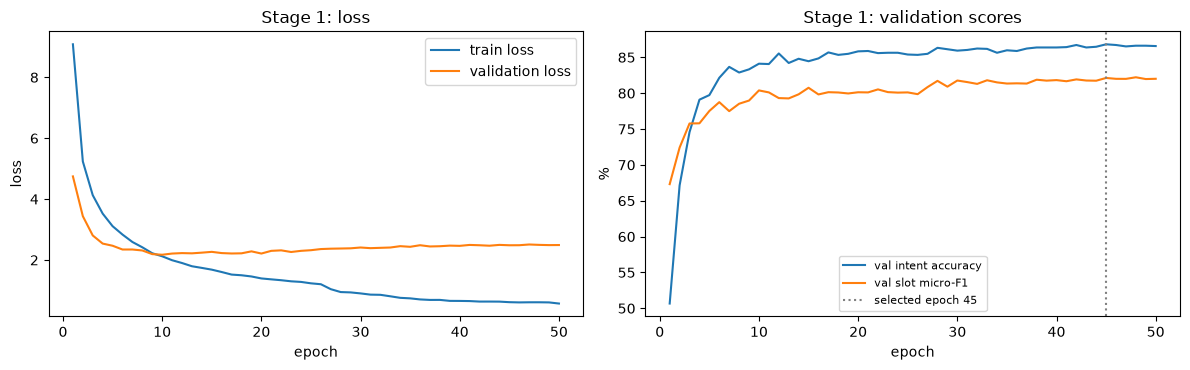

In [17]:
plot_history(hist1, best1["epoch"], "Stage 1", os.path.join(FIG_DIR, "stage1_learning_curves.png"))

### 6.6 Final evaluation of the Stage 1 checkpoint

The saved checkpoint is reloaded into a fresh model. Its validation counts must equal the ones logged for the selected
epoch (asserted), and only then is the test split unlocked and scored, once.

In [18]:
ck1 = torch.load(S1_CKPT, map_location=DEVICE, weights_only=False)
stage1_final = Stage1IDCNN(ck1["config"], feats1).to(DEVICE)
stage1_final.load_state_dict(ck1["state"])
dev_res1 = evaluate(stage1_final, dev1_batches, data["dev"])
for key in ("intent_correct", "tp", "fp", "fn"):
    assert dev_res1[key] == ck1["dev"][key], f"reloaded checkpoint disagrees with the logged best epoch on {key}"
print(f"Reloaded {S1_CKPT} (epoch {ck1['epoch']}): validation scores identical to the selected epoch.")

TEST_UNLOCKED["stage1"] = True            # the Stage 1 model is frozen from here on
check_split_allowed("test", "stage1")
test1_batches = make_batches(encode_stage1(data["test"], feats1), 256, shuffle=False)
test_res1 = evaluate(stage1_final, test1_batches, data["test"])
for split, r in (("Validation", dev_res1), ("Test", test_res1)):
    print(f"Stage 1 | {split:<10} | intent accuracy {r['intent_acc']:.2f} | slot micro-F1 {r['slot_f1']:.2f} | "
          f"TP {r['tp']} FP {r['fp']} FN {r['fn']}")

Reloaded checkpoints/stage1_best.pt (epoch 45): validation scores identical to the selected epoch.


Stage 1 | Validation | intent accuracy 86.82 | slot micro-F1 82.12 | TP 1686 FP 409 FN 325
Stage 1 | Test       | intent accuracy 85.57 | slot micro-F1 79.31 | TP 2254 FP 615 FN 561


## 7. Stage 2: AI-collaborative diagnosis and improvement

The AI collaboration is summarised in the report (chat history submitted separately as `ai_collaboration.md`). The process was:
**diagnose** the frozen Stage 1 model on the validation split, **propose** changes that target each weakness,
**test** each change on the validation split (`stage2_experiments.ipynb`), and keep only what helped.

### 7.1 Diagnosis of the Stage 1 model (validation split only)

In [19]:
@torch.no_grad()
def predict_tags(model, batches, examples):
    """Predicted intents and tag sequences (strings), in dataset order."""
    model.eval()
    intents, tags = [], []
    for batch in batches:
        batch = to_device(batch)
        ids, paths = model.decode(batch, model.compute(batch))
        intents += [intent_vocab.itos[i] for i in ids]
        tags += [[tag_vocab.itos[t] for t in p] for p in paths]
    return intents, tags


def diagnose(pred_intents, pred_tags, examples, train_examples, unit_vocab, split_fn=whitespace_units):
    """Error analysis on the validation split. Returns the numbers that motivate each Stage 2 change."""
    allowed = slot_types_per_intent(train_examples)
    pred_spans = [tags_to_spans(e["tokens"], t) for e, t in zip(examples, pred_tags)]
    report = {}

    # 1. Intent errors: which pairs, and do they cross scenarios?
    errs = [(e["intent"], p) for e, p in zip(examples, pred_intents) if p != e["intent"]]
    cross = sum(g.split("_", 1)[0] != p.split("_", 1)[0] for g, p in errs)
    report["intent_errors"], report["intent_errors_cross_scenario"] = len(errs), cross
    print(f"Intent errors: {len(errs)} / {len(examples)}; {cross} ({100 * cross / max(1, len(errs)):.1f}%) predict an "
          f"intent from a different scenario.")
    print("Most frequent confusions (gold -> predicted):")
    for (g, p), c in Counter(errs).most_common(8):
        print(f"  {c:3d}  {g} -> {p}")

    # 2. Slot errors by kind
    kinds = Counter()
    for gold, pred in zip((e["gold_spans"] for e in examples), pred_spans):
        fp, fn = pred - gold, gold - pred
        for t, s in fn:
            if any(s == ps for pt, ps in fp):
                kinds["right span, wrong type"] += 1
            elif any(t == pt and (s in ps or ps in s) for pt, ps in fp):
                kinds["right type, wrong boundary"] += 1
            else:
                kinds["missed entirely"] += 1
        for t, s in fp:
            if not any(s == gs or (t == gt and (s in gs or gs in s)) for gt, gs in fn):
                kinds["spurious slot"] += 1
    report["slot_error_kinds"] = dict(kinds)
    print("\nSlot error kinds:", dict(kinds))

    # 3. Per slot type (lowest F1 among types with at least 20 gold slots)
    tp, fp, fn = Counter(), Counter(), Counter()
    for e, pred in zip(examples, pred_spans):
        for t, _ in pred & e["gold_spans"]:
            tp[t] += 1
        for t, _ in pred - e["gold_spans"]:
            fp[t] += 1
        for t, _ in e["gold_spans"] - pred:
            fn[t] += 1
    f1 = {t: 200 * tp[t] / max(1, 2 * tp[t] + fp[t] + fn[t]) for t in set(tp) | set(fn)}
    weak = sorted([t for t in f1 if tp[t] + fn[t] >= 20], key=f1.get)[:8]
    report["weak_slot_types"] = {t: round(f1[t], 1) for t in weak}
    print("Weakest slot types (support >= 20):", ", ".join(f"{t} {f1[t]:.1f}" for t in weak))

    # 4. Unseen words
    def has_unseen(e):
        return any(u not in unit_vocab.stoi for t in e["tokens"] for u in split_fn(t))
    for flag in (True, False):
        idx = [i for i, e in enumerate(examples) if has_unseen(e) == flag]
        s = score([pred_intents[i] for i in idx], [pred_spans[i] for i in idx], [examples[i] for i in idx])
        report[f"unseen_{flag}"] = {"n": len(idx), "intent_acc": s["intent_acc"], "slot_f1": s["slot_f1"]}
        print(f"{'With' if flag else 'Without'} a word unseen in train: {len(idx):4d} utterances | intent "
              f"{s['intent_acc']:.2f} | slot F1 {s['slot_f1']:.2f}")
    apos = [i for i, e in enumerate(examples) if any("'" in t for t in e["tokens"])]
    s = score([pred_intents[i] for i in apos], [pred_spans[i] for i in apos], [examples[i] for i in apos])
    report["apostrophe"] = {"n": len(apos), "slot_f1": s["slot_f1"]}
    print(f"Utterances containing an apostrophe word (what's, john's): {len(apos)} | slot F1 {s['slot_f1']:.2f}")

    # 5. Structural errors the decoder could rule out
    invalid = sum(any(t.startswith("I-") and (j == 0 or tags[j - 1][2:] != t[2:] or tags[j - 1] == "O")
                      for j, t in enumerate(tags)) for tags in pred_tags)
    incompatible = sum(any(not allowed[intent_vocab.stoi[p], tag_vocab.stoi[t]] for t in tags)
                       for p, tags in zip(pred_intents, pred_tags))
    report["invalid_bio"], report["slot_type_never_seen_with_intent"] = invalid, incompatible
    print(f"\nUtterances with an invalid BIO sequence: {invalid}")
    print(f"Utterances with a slot type never seen with the predicted intent in train: {incompatible}")

    # 6. Coupling between the tasks
    right = [i for i, e in enumerate(examples) if pred_intents[i] == e["intent"]]
    wrong = [i for i, e in enumerate(examples) if pred_intents[i] != e["intent"]]
    for name, idx in (("intent right", right), ("intent wrong", wrong)):
        s = score([pred_intents[i] for i in idx], [pred_spans[i] for i in idx], [examples[i] for i in idx])
        report[f"slot_f1_{name.replace(' ', '_')}"] = s["slot_f1"]
        print(f"Slot F1 when {name}: {s['slot_f1']:.2f} ({len(idx)} utterances)")
    return report

In [20]:
s1_dev_intents, s1_dev_tags = predict_tags(stage1_final, dev1_batches, data["dev"])
diag1 = diagnose(s1_dev_intents, s1_dev_tags, data["dev"], data["train"], feats1["words"])
json.dump(diag1, open("results/stage1_dev_diagnosis.json", "w"), indent=1, default=str)

Intent errors: 268 / 2033; 190 (70.9%) predict an intent from a different scenario.
Most frequent confusions (gold -> predicted):
    7  general_quirky -> qa_factoid
    7  general_quirky -> news_query
    6  qa_factoid -> general_quirky
    5  news_query -> qa_factoid
    5  general_quirky -> datetime_query
    5  calendar_query -> recommendation_events
    4  play_music -> play_radio
    4  general_quirky -> weather_query

Slot error kinds: {'missed entirely': 164, 'right type, wrong boundary': 97, 'spurious slot': 248, 'right span, wrong type': 64}
Weakest slot types (support >= 20): news_topic 48.2, radio_name 57.1, song_name 63.6, food_type 70.8, player_setting 74.3, business_type 74.3, artist_name 74.4, list_name 75.9
With a word unseen in train:  364 utterances | intent 77.20 | slot F1 69.43
Without a word unseen in train: 1669 utterances | intent 88.92 | slot F1 85.17
Utterances containing an apostrophe word (what's, john's): 164 | slot F1 78.18

Utterances with an invalid BIO 

**What the diagnosis says, and the response to each finding**

| Finding on the validation split | Stage 2 response |
|---|---|
| Utterances containing a word unseen in training score far lower on both tasks (see the "With a word unseen in train" line) | Clitic-aware sub-tokens (`what's` -> `what 's`, `wyatt's` -> `wyatt 's`, `p.` -> `p`) so the stem matches a pre-trained vector; frozen GloVe and fastText rows for train words plus GloVe's most frequent words; hashed character n-grams |
| Most intent errors cross scenarios (for example `general_quirky -> qa_factoid`) | A scenario head (18 classes, labels derived from the intent label) whose log-probabilities are added to the intent head's |
| Slot F1 is much lower when the intent is wrong | Intent-aware slot emissions: the predicted intent distribution selects a learned intent embedding that is added to every token before the slot layer |
| Invalid BIO sequences (an `I-x` with no `B-x`) | Hard BIO constraints in the CRF |
| Training loss keeps falling while validation loss rises (Section 6.5) | Smaller, more regularised members (dropout 0.4, label smoothing 0.1), weight averaging over the last 10 epochs, and an ensemble of members that differ only in their random seed |

Changes that were tried and **not** kept (validation evidence in `stage2_experiments.ipynb`): a self-attention layer
on top of the convolutions, R-Drop consistency regularisation, joint re-ranking of the top-3 intents with slot-type
masking, kNN retrieval over training-set sentence vectors, fine-tuned (instead of frozen) word vectors, and wider
(256-channel) members.

### 7.2 Stage 2 tokenisation and inputs

A token is split into units for the encoder, but tags stay on the original whitespace tokens: the encoder output at each
token's **first** unit is used for its slot tag, so spans and scoring are exactly as in Stage 1.

In [21]:
CLITIC_RE = re.compile(r"^(.+?)(n't|'s|'re|'ve|'ll|'d|'m)$")


def clitic_units(token):
    """Split one whitespace token into sub-units the way GloVe's corpus was tokenised:
    what's -> what 's, don't -> do n't, wyatt's -> wyatt 's, and spelled-out letters p. -> p."""
    if re.fullmatch(r"[a-z]\.", token):
        return [token[0]]
    m = CLITIC_RE.match(token)
    if m:
        return [m.group(1), m.group(2)]
    return [token]


def split_units(tokens, split_fn):
    """Units for the encoder plus, for each original token, the index of its first unit."""
    units, first = [], []
    for t in tokens:
        first.append(len(units))
        units.extend(split_fn(t))
    return units, first


for tok, expect in [("what's", ["what", "'s"]), ("don't", ["do", "n't"]), ("wyatt's", ["wyatt", "'s"]),
                    ("p.", ["p"]), ("o'clock", ["o'clock"]), ("mr.", ["mr."]), ("alarm", ["alarm"])]:
    assert clitic_units(tok) == expect, (tok, clitic_units(tok))
u, f = split_units("what's my brother's schedule".split(), clitic_units)
assert u == ["what", "'s", "my", "brother", "'s", "schedule"] and f == [0, 2, 3, 5]
print("Tokeniser checks passed:", list(zip("what's my brother's schedule".split(), f)))

Tokeniser checks passed: [("what's", 0), ('my', 2), ("brother's", 3), ('schedule', 5)]


In [22]:
def char_ngrams(unit, buckets, n_min=3, n_max=5, max_grams=40):
    """fastText-style hashed character n-grams of '<unit>' (plus the whole marked word), ids 1..buckets."""
    w = f"<{unit}>"
    grams = [w] + [w[i:i + n] for n in range(n_min, n_max + 1) for i in range(len(w) - n + 1)]
    return [1 + zlib.crc32(g.encode("utf-8")) % buckets for g in grams[:max_grams]]


def build_stage2_features(train_examples, split_fn, sources, top_words, word_drop_alpha, ngram_buckets):
    """Vocabularies come from train only. The frozen table holds every train unit plus the most frequent
    words in GloVe's own ranking (`top_words`), so unseen dev/test words can still hit a pre-trained vector."""
    counts = Counter(u for e in train_examples for t in e["tokens"] for u in split_fn(t))
    units = Vocab(by_frequency(counts))
    chars = Vocab(sorted({c for u in counts for c in u}))
    frozen_words = Vocab(units.itos[2:] + [w for w in top_words if w not in units.stoi])
    dim = 300 * len(sources)
    table = np.zeros((len(frozen_words), dim), dtype=np.float32)
    hits = np.zeros(len(frozen_words), dtype=bool)
    for j, (name, vecs) in enumerate(sources.items()):
        for i, w in enumerate(frozen_words.itos[2:], start=2):
            v = lookup_vector(w, vecs)
            if v is not None:
                table[i, 300 * j:300 * (j + 1)] = v
                hits[i] = True
    drop_p = torch.zeros(len(units))
    for i, w in enumerate(units.itos[2:], start=2):
        drop_p[i] = word_drop_alpha / (word_drop_alpha + counts[w])
    first = next(iter(sources.values()))
    unit_init = np.random.RandomState(0).normal(0, 0.3, (len(units), 300)).astype(np.float32)
    unit_init[0] = 0
    for i, w in enumerate(units.itos[2:], start=2):
        v = lookup_vector(w, first)
        if v is not None:
            unit_init[i] = v
    return {"split_fn": split_fn, "units": units, "chars": chars, "frozen_words": frozen_words,
            "unit_init": torch.tensor(unit_init),
            "table": torch.tensor(table), "frozen_hit": torch.tensor(hits), "drop_p": drop_p,
            "ngram_buckets": ngram_buckets, "sources": list(sources)}


def encode_stage2(examples, feats, max_chars=20):
    out = []
    for e in examples:
        units, first = split_units(e["tokens"], feats["split_fn"])
        item = {"units": [feats["units"].get(u) for u in units],
                "frozen": [feats["frozen_words"].get(u) for u in units],
                "chars": [[feats["chars"].get(c) for c in u[:max_chars]] for u in units],
                "first": first, "tags": [tag_vocab.stoi[t] for t in e["tags"]],
                "intent": intent_vocab.stoi[e["intent"]], "scenario": scenario_vocab.stoi[e["scenario"]]}
        if feats["ngram_buckets"]:
            item["grams"] = [char_ngrams(u, feats["ngram_buckets"]) for u in units]
        out.append(item)
    return out


def coverage_report(feats, examples, name):
    units = [u for e in examples for t in e["tokens"] for u in feats["split_fn"](t)]
    unseen = [u for u in units if u not in feats["units"].stoi]
    has_vec = [u for u in unseen if u in feats["frozen_words"].stoi and bool(feats["frozen_hit"][feats["frozen_words"].stoi[u]])]
    print(f"{name}: {len(units):,} units | unseen in train {100 * len(unseen) / len(units):.2f}% | "
          f"of those, covered by a frozen pre-trained vector {100 * len(has_vec) / max(1, len(unseen)):.1f}%")

In [23]:
S2_BASE = dict(channels=192, dilations=[1, 2, 4, 8, 1, 2], dropout=0.4, task_dim=100, use_char=True, ngram_dim=50,
               ngram_buckets=5000, use_frozen=True, sources=["glove", "fasttext"], top_k=2000, tokeniser="clitic",
               attn_layers=0, attn_heads=4, hier=True, scen_weight=0.5, intent_aware=True, bio_constraints=True,
               label_smoothing=0.1, slot_weight=1.0, lr=1e-3, weight_decay=0.01, batch_size=32, max_epochs=40,
               schedule="cosine", warmup_epochs=1, swa_start=30, early_stop=100, clip=5.0,
               joint_k=1, slot_mask=False, word_drop_alpha=0.25)
s2_units = {u for e in data["train"] for t in e["tokens"] for u in clitic_units(t)}
glove_s2, glove_top = read_vectors(ensure_glove(), needed_keys(s2_units), top_k=S2_BASE["top_k"])
fasttext_s2, _ = read_vectors(ensure_fasttext(), needed_keys(s2_units) | set(glove_top))
feats2 = build_stage2_features(data["train"], clitic_units, {"glove": glove_s2, "fasttext": fasttext_s2}, glove_top,
                               S2_BASE["word_drop_alpha"], S2_BASE["ngram_buckets"])
feats2["allowed_tags"] = slot_types_per_intent(data["train"])
print(f"Stage 2 unit vocabulary (train only): {len(feats2['units']):,} | frozen vector rows: {len(feats2['frozen_words']):,} "
      f"(train units + GloVe's {S2_BASE['top_k']:,} most frequent words) x {feats2['table'].shape[1]} dims")
coverage_report(feats2, data["dev"], "dev")
train2 = encode_stage2(data["train"], feats2)
dev2_batches = make_batches(encode_stage2(data["dev"], feats2), 256, shuffle=False)

Stage 2 unit vocabulary (train only): 5,153 | frozen vector rows: 5,871 (train units + GloVe's 2,000 most frequent words) x 600 dims
dev: 14,128 units | unseen in train 3.18% | of those, covered by a frozen pre-trained vector 14.9%


### 7.3 Stage 2 model and parameter count

**One member.** Units are represented by [frozen GloVe ; frozen fastText] (600-d, shared by all members) + a 100-d
trainable embedding (with frequency-based `<unk>` replacement) + a char-CNN + the mean of 50-d hashed character
3-to-5-gram embeddings (fastText-style, learned from train). A projection to 192 channels feeds six residual **gated**
dilated convolutions (dilation 1, 2, 4, 8, 1, 2): each computes `A * sigmoid(B)` from a width-3 convolution
(Dauphin et al., 2017), so every channel learns how much of its new evidence to let through.

**Heads.**
* Intent: mean + max pooling, Linear, ReLU, dropout. An intent layer (60) and a scenario layer (18) read the same
  vector; final intent score = log p(intent) + log p(scenario of that intent).
* Slots: tokens are read at their first unit, the intent distribution selects an intent embedding that is added to each
  token, then Linear, ReLU, dropout, Linear to 111 emissions, decoded by a CRF in which illegal BIO transitions are
  penalised by -10,000.

**Loss.** Intent cross-entropy with label smoothing 0.1 + 0.5 x scenario cross-entropy + CRF negative log-likelihood.

**Ensemble.** Members differ only in their random seed. Intent: average of member probabilities. Slots: Viterbi on the
averaged emission and transition scores, which is the tag path with the highest summed member score. All members share
one frozen word-vector table, which is counted once.

In [24]:
class GLUBlock(nn.Module):
    """Residual gated dilated convolution (Dauphin et al., 2017): x + dropout(GLU(conv(x))), then layer norm.
    The gate decides, per channel and position, how much of the convolution's output to let through."""

    def __init__(self, channels, dilation, width=3, dropout=0.3):
        super().__init__()
        self.conv = SeqConv(channels, 2 * channels, width, dilation)
        self.norm = nn.LayerNorm(channels)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, m):
        return self.norm(x + self.drop(F.glu(self.conv(x), dim=2))) * m


def make_frozen_embedding(table):
    emb = nn.Embedding.from_pretrained(table.clone(), freeze=True, padding_idx=0)
    return emb


def joint_decode(intent_logprobs, em, mask, potentials, allowed_tags, k, use_mask):
    """Pick the intent and the tag path together. For each of the top-k intents, slot types never seen with that
    intent in train are masked out, Viterbi finds the best path, and the pair with the highest
    log p(intent) + log p(path | utterance) wins. k=1 without masking is plain argmax + Viterbi."""
    trans, start, end = potentials
    if k <= 1 and not use_mask:
        paths, _ = crf_viterbi(em, mask, trans, start, end)
        return intent_logprobs.argmax(1).tolist(), paths
    B, T, K = em.shape
    k = max(1, k)
    top_lp, top_i = intent_logprobs.topk(k, dim=1)                                   # (B, k)
    em_k = em.unsqueeze(1).expand(B, k, T, K).reshape(B * k, T, K)
    if use_mask:
        em_k = em_k + (~allowed_tags[top_i.reshape(-1)]).float().unsqueeze(1) * -1e4
    mask_k = mask.repeat_interleave(k, dim=0)
    paths, best = crf_viterbi(em_k, mask_k, trans, start, end)
    log_z = crf_log_partition(em, mask, trans, start, end)
    total = top_lp + best.view(B, k) - log_z.unsqueeze(1)
    choice = total.argmax(1).tolist()
    return [int(top_i[b, c]) for b, c in enumerate(choice)], [paths[b * k + c] for b, c in enumerate(choice)]


class Stage2Net(nn.Module):
    """Joint gated dilated CNN.
    Each unit is represented by [frozen GloVe ; fastText] (+ trainable task embedding, char-CNN, hashed char n-grams).
    That passes through residual GLU dilated convolutions (+ optional self-attention), then three heads:
    intent (+ scenario, combined hierarchically), and intent-aware slot emissions decoded by a BIO-constrained CRF."""

    def __init__(self, cfg, feats, frozen):
        super().__init__()
        self.cfg, C = cfg, cfg["channels"]
        in_dim = 0
        self.frozen = frozen if cfg["use_frozen"] else None
        if self.frozen is not None:
            in_dim += frozen.embedding_dim
        self.task_emb = nn.Embedding(len(feats["units"]), cfg["task_dim"], padding_idx=0) if cfg["task_dim"] else None
        if cfg.get("task_glove_init"):           # fine-tuned word embedding, initialised from the first vector source
            assert cfg["task_dim"] == 300
            self.task_emb.weight.data.copy_(feats["unit_init"])
        in_dim += cfg["task_dim"]
        self.char_cnn = CharCNN(len(feats["chars"])) if cfg["use_char"] else None
        in_dim += self.char_cnn.out_dim if self.char_cnn is not None else 0
        self.ngram = nn.Embedding(feats["ngram_buckets"] + 1, cfg["ngram_dim"], padding_idx=0) if cfg["ngram_dim"] else None
        in_dim += cfg["ngram_dim"]
        self.in_drop = nn.Dropout(cfg["dropout"])
        self.proj = nn.Linear(in_dim, C)
        self.blocks = nn.ModuleList([GLUBlock(C, d, 3, cfg["dropout"]) for d in cfg["dilations"]])
        self.attn = nn.ModuleList([nn.TransformerEncoderLayer(C, cfg["attn_heads"], 2 * C, cfg["dropout"], batch_first=True)
                                   for _ in range(cfg["attn_layers"])])
        self.intent_hidden = nn.Sequential(nn.Linear(2 * C, C), nn.ReLU(), nn.Dropout(cfg["dropout"]))
        self.intent_out = nn.Linear(C, len(intent_vocab))
        self.scen_out = nn.Linear(C, len(scenario_vocab)) if cfg["hier"] else None
        self.intent_label_emb = nn.Embedding(len(intent_vocab), C) if cfg["intent_aware"] else None
        self.slot_head = nn.Sequential(nn.Linear(C, C), nn.ReLU(), nn.Dropout(cfg["dropout"]), nn.Linear(C, len(tag_vocab)))
        self.crf = CRF(len(tag_vocab), bio_constraints(tag_vocab.itos) if cfg["bio_constraints"] else None)
        self.register_buffer("drop_p", feats["drop_p"])
        self.register_buffer("i2s", intent_to_scenario.clone())
        self.register_buffer("allowed_tags", feats["allowed_tags"].clone())

    def encode(self, batch):
        ids, umask = batch["units"], batch["units"] != 0
        m = umask.unsqueeze(2).float()
        parts = []
        if self.frozen is not None:
            parts.append(self.frozen(batch["frozen"]))
        if self.task_emb is not None:
            tids = ids
            if self.training:
                tids = ids.masked_fill((torch.rand(ids.shape, device=ids.device) < self.drop_p[ids]) & umask, 1)
            parts.append(self.task_emb(tids))
        if self.char_cnn is not None:
            parts.append(self.char_cnn(batch["chars"]))
        if self.ngram is not None:
            g = batch["grams"]
            parts.append(self.ngram(g).sum(2) / (g != 0).sum(2, keepdim=True).clamp(min=1))
        x = self.proj(self.in_drop(torch.cat(parts, dim=2))) * m
        for blk in self.blocks:
            x = blk(x, m)
        for layer in self.attn:
            x = layer(x, src_key_padding_mask=~umask) * m
        return x, umask

    def compute(self, batch):
        hu, umask = self.encode(batch)
        z = self.intent_hidden(masked_mean_max(hu, umask))
        logits = self.intent_out(z)
        out = {"z": z}
        if self.scen_out is not None:
            out["scen_logits"] = self.scen_out(z)
            logits = F.log_softmax(logits, 1) + F.log_softmax(out["scen_logits"], 1)[:, self.i2s]
        out["intent_logits"] = logits
        C = hu.size(2)
        T = int(batch["lengths"].max())
        ht = hu.gather(1, batch["first"][:, :T].unsqueeze(2).expand(-1, -1, C))
        tmask = torch.arange(T, device=hu.device).unsqueeze(0) < batch["lengths"].to(hu.device).unsqueeze(1)
        if self.intent_label_emb is not None:
            ht = ht + (F.softmax(logits, 1) @ self.intent_label_emb.weight).unsqueeze(1)
        out["emissions"] = self.slot_head(ht)
        out["mask"] = tmask
        return out

    def loss(self, batch, out):
        cfg = self.cfg
        T = out["mask"].size(1)
        loss = F.cross_entropy(out["intent_logits"], batch["intent"], label_smoothing=cfg["label_smoothing"])
        if "scen_logits" in out:
            loss = loss + cfg["scen_weight"] * F.cross_entropy(out["scen_logits"], batch["scenario"])
        nll = self.crf.nll(out["emissions"], batch["tags"][:, :T], out["mask"]).mean()
        return loss + cfg["slot_weight"] * nll

    def train_loss(self, batch):
        """Training loss. With cfg['rdrop'] > 0 (R-Drop, Liang et al. 2021) the batch goes through the network twice
        with different dropout masks, and the two predicted distributions (intent, and per-token tag scores) are
        pulled together by a symmetric KL term. This discourages predictions that depend on which units dropout kept."""
        out1 = self.compute(batch)
        loss = self.loss(batch, out1)
        alpha = self.cfg.get("rdrop", 0.0)
        if not alpha:
            return loss
        out2 = self.compute(batch)
        loss = (loss + self.loss(batch, out2)) / 2

        def sym_kl(a, b):
            pa, pb = F.log_softmax(a, -1), F.log_softmax(b, -1)
            return 0.5 * ((pa.exp() * (pa - pb)).sum(-1) + (pb.exp() * (pb - pa)).sum(-1))
        kl_intent = sym_kl(out1["intent_logits"], out2["intent_logits"]).mean()
        m = out1["mask"].float()
        kl_tags = (sym_kl(out1["emissions"], out2["emissions"]) * m).sum() / m.size(0)
        return loss + alpha * (kl_intent + kl_tags)

    def intent_logprobs(self, out):
        return F.log_softmax(out["intent_logits"], 1)

    def decode(self, batch, out):
        return joint_decode(self.intent_logprobs(out), out["emissions"], out["mask"], self.crf.potentials(),
                            self.allowed_tags, self.cfg["joint_k"], self.cfg["slot_mask"])

In [25]:
class Ensemble(nn.Module):
    """Several Stage2Net members that share one frozen word-vector table. Intent: average of member probabilities.
    Slots: Viterbi on the averaged emissions and transition scores (the path maximising the summed member scores).
    Optional kNN over the training set mixes the labels of the nearest train utterances into the intent distribution."""

    def __init__(self, members):
        super().__init__()
        self.members = nn.ModuleList(members)
        self.cfg = dict(members[0].cfg)
        self.knn_k, self.knn_lambda, self.knn_temp = 0, 0.0, 0.05

    def compute(self, batch):
        outs = [m.compute(batch) for m in self.members]
        probs = torch.stack([F.softmax(o["intent_logits"], 1) for o in outs]).mean(0)
        return {"members": outs, "intent_probs": probs, "mask": outs[0]["mask"],
                "emissions": torch.stack([o["emissions"] for o in outs]).mean(0),
                "z": [F.normalize(o["z"], dim=1) for o in outs]}

    def potentials(self):
        pots = [m.crf.potentials() for m in self.members]
        return tuple(torch.stack(p).mean(0) for p in zip(*pots))

    def loss(self, batch, out):
        return torch.stack([m.loss(batch, o) for m, o in zip(self.members, out["members"])]).mean()

    @torch.no_grad()
    def build_knn(self, batches, labels, k, lam, temp):
        """Store each member's normalised sentence vector for every *training* utterance (no other split)."""
        self.eval()
        keys = [[] for _ in self.members]
        for batch in batches:
            out = self.compute(to_device(batch))
            for j, z in enumerate(out["z"]):
                keys[j].append(z)
        self.register_buffer("knn_keys", torch.stack([torch.cat(kj) for kj in keys]))     # (members, N, C)
        self.register_buffer("knn_labels", torch.tensor(labels, device=self.knn_keys.device))
        self.knn_k, self.knn_lambda, self.knn_temp = k, lam, temp

    def intent_logprobs(self, out):
        p = out["intent_probs"]
        if self.knn_k and self.knn_lambda > 0:
            sims = torch.stack([z @ keys.T for z, keys in zip(out["z"], self.knn_keys)]).mean(0)   # (B, N)
            top_s, top_j = sims.topk(self.knn_k, dim=1)
            w = F.softmax(top_s / self.knn_temp, dim=1)
            knn = torch.zeros_like(p).scatter_add_(1, self.knn_labels[top_j], w)
            p = (1 - self.knn_lambda) * p + self.knn_lambda * knn
        return torch.log(p.clamp(min=1e-12))

    def decode(self, batch, out):
        return joint_decode(self.intent_logprobs(out), out["emissions"], out["mask"], self.potentials(),
                            self.members[0].allowed_tags, self.cfg["joint_k"], self.cfg["slot_mask"])

In [26]:
S2_SEEDS = [42, 43, 44, 45, 46, 47]
frozen2 = make_frozen_embedding(feats2["table"]).to(DEVICE)     # one frozen table, shared by every member
members2 = []
for seed in S2_SEEDS:
    set_seed(seed)
    members2.append(Stage2Net({**S2_BASE, "seed": seed}, feats2, frozen2).to(DEVICE))
system2 = Ensemble(members2)
print(members2[0])
total2, trainable2 = count_params(system2)
per_member = count_params(members2[0])[1]
print(f"\nStage 2 pipeline: {len(members2)} members x {per_member:,} trainable + one shared frozen table of "
      f"{feats2['table'].numel():,} word-vector values")
print(f"Stage 2 pipeline parameters: total {total2:,} | trainable {trainable2:,}")
assert total2 <= 20_000_000, "over the 20M parameter cap"
print("Within the 20M cap.")

Stage2Net(
  (frozen): Embedding(5871, 600, padding_idx=0)
  (task_emb): Embedding(5153, 100, padding_idx=0)
  (char_cnn): CharCNN(
    (emb): Embedding(34, 50, padding_idx=0)
    (conv): SeqConv(
      (lin): Linear(in_features=150, out_features=100, bias=True)
    )
  )
  (ngram): Embedding(5001, 50, padding_idx=0)
  (in_drop): Dropout(p=0.4, inplace=False)
  (proj): Linear(in_features=850, out_features=192, bias=True)
  (blocks): ModuleList(
    (0-5): 6 x GLUBlock(
      (conv): SeqConv(
        (lin): Linear(in_features=576, out_features=384, bias=True)
      )
      (norm): LayerNorm((192,), eps=1e-05, elementwise_affine=True, bias=True)
      (drop): Dropout(p=0.4, inplace=False)
    )
  )
  (attn): ModuleList()
  (intent_hidden): Sequential(
    (0): Linear(in_features=384, out_features=192, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.4, inplace=False)
  )
  (intent_out): Linear(in_features=192, out_features=60, bias=True)
  (scen_out): Linear(in_features=192, out_features=

### 7.4 Training the members (train split only) and selecting the checkpoint

Each member: AdamW (learning rate 1e-3, weight decay 0.01), one warm-up epoch then cosine decay over 40 epochs, batch
size 32, clipping at 5. From epoch 30 the running average of the weights (SWA) is also scored on validation after every
epoch; for each member the better of "single epoch" and "weight average" by validation combined score is kept.

In [27]:
hist2, best2 = [], []
for k, (seed, member) in enumerate(zip(S2_SEEDS, members2)):
    print(f"\n=== Member {k} (seed {seed}) ===")
    path = os.path.join(CKPT_DIR, f"stage2_member{k}.pt")
    h, b = fit(member, member.cfg, train2, dev2_batches, data["dev"], path)
    member.load_state_dict(torch.load(path, map_location=DEVICE, weights_only=False)["state"])
    hist2.append(h)
    best2.append(b)
    print(f"Member {k}: selected epoch {b['epoch']} ({'weight average' if b['kind'] == 'swa' else 'single epoch'}) | "
          f"dev combined {b['combined']:.2f} | training time {b['train_time_s'] / 60:.1f} min")
json.dump(hist2, open("results/stage2_histories.json", "w"), indent=1)


=== Member 0 (seed 42) ===


epoch  1 | train loss 11.0994 | dev loss 4.4121 | intent 54.40 | slot F1 66.53 | combined 60.47 | 17.6s  <- saved (raw)


epoch  2 | train loss 4.4373 | dev loss 3.3189 | intent 73.59 | slot F1 74.92 | combined 74.25 | 16.5s  <- saved (raw)


epoch  3 | train loss 3.5280 | dev loss 3.0022 | intent 79.29 | slot F1 77.24 | combined 78.27 | 16.7s  <- saved (raw)


epoch  4 | train loss 3.1028 | dev loss 2.8370 | intent 80.87 | slot F1 78.53 | combined 79.70 | 17.3s  <- saved (raw)


epoch  5 | train loss 2.8272 | dev loss 2.8431 | intent 81.90 | slot F1 80.02 | combined 80.96 | 16.6s  <- saved (raw)


... (231 outputs left out)

epoch 37 | train loss 1.0807 | dev loss 3.1933 | intent 87.21 | slot F1 82.50 | combined 84.86 | swa comb 84.89 | 20.8s


epoch 38 | train loss 1.0791 | dev loss 3.1924 | intent 87.26 | slot F1 82.48 | combined 84.87 | swa comb 84.94 | 21.7s  <- saved (swa)


epoch 39 | train loss 1.0845 | dev loss 3.1928 | intent 87.21 | slot F1 82.45 | combined 84.83 | swa comb 84.91 | 22.0s


epoch 40 | train loss 1.0797 | dev loss 3.1932 | intent 87.21 | slot F1 82.45 | combined 84.83 | swa comb 84.93 | 21.7s
Member 5: selected epoch 38 (weight average) | dev combined 84.94 | training time 13.3 min


In [28]:
dev_res2_members = [evaluate(Ensemble([m]), dev2_batches, data["dev"]) for m in members2]
dev_res2 = evaluate(system2, dev2_batches, data["dev"])
for k, r in enumerate(dev_res2_members):
    print(f"member {k}      | dev intent {r['intent_acc']:.2f} | slot F1 {r['slot_f1']:.2f} | combined {r['combined']:.2f}")
print(f"ensemble ({len(members2)}) | dev intent {dev_res2['intent_acc']:.2f} | slot F1 {dev_res2['slot_f1']:.2f} | "
      f"combined {dev_res2['combined']:.2f}")
S2_CKPT = os.path.join(CKPT_DIR, "stage2_best.pt")
S2_EPOCHS = "/".join(str(b["epoch"]) for b in best2)
torch.save({"state": system2.state_dict(), "config": S2_BASE, "seeds": S2_SEEDS, "member_best": best2,
            "dev": dev_res2}, S2_CKPT)
print(f"\nSelected Stage 2 checkpoint: {len(members2)}-member ensemble | member epochs {S2_EPOCHS} | "
      f"dev intent acc {dev_res2['intent_acc']:.2f} | dev slot F1 {dev_res2['slot_f1']:.2f} | "
      f"dev combined {dev_res2['combined']:.2f} | file {S2_CKPT}")

member 0      | dev intent 87.01 | slot F1 82.28 | combined 84.65
member 1      | dev intent 87.31 | slot F1 82.55 | combined 84.93
member 2      | dev intent 87.65 | slot F1 82.84 | combined 85.25
member 3      | dev intent 87.16 | slot F1 82.43 | combined 84.80
member 4      | dev intent 87.16 | slot F1 82.65 | combined 84.91
member 5      | dev intent 87.36 | slot F1 82.52 | combined 84.94
ensemble (6) | dev intent 88.59 | slot F1 83.65 | combined 86.12

Selected Stage 2 checkpoint: 6-member ensemble | member epochs 32/39/40/33/39/38 | dev intent acc 88.59 | dev slot F1 83.65 | dev combined 86.12 | file checkpoints/stage2_best.pt


### 7.5 Learning curves

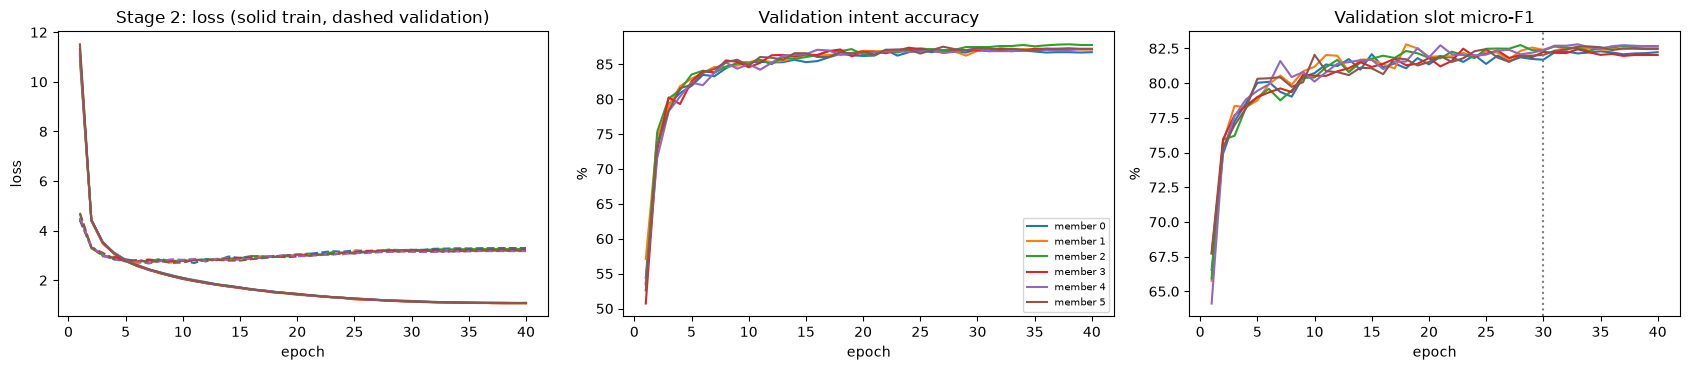

In [29]:
fig, ax = plt.subplots(1, 3, figsize=(17, 3.8))
for k, h in enumerate(hist2):
    ep = [r["epoch"] for r in h]
    ax[0].plot(ep, [r["train_loss"] for r in h], color=f"C{k}", label=f"member {k} train")
    ax[0].plot(ep, [r["dev_loss"] for r in h], color=f"C{k}", ls="--", label=f"member {k} val")
    ax[1].plot(ep, [r["dev_intent_acc"] for r in h], color=f"C{k}", label=f"member {k}")
    ax[2].plot(ep, [r["dev_slot_f1"] for r in h], color=f"C{k}", label=f"member {k}")
for a, title, yl in zip(ax, ["Stage 2: loss (solid train, dashed validation)", "Validation intent accuracy",
                             "Validation slot micro-F1"], ["loss", "%", "%"]):
    a.set_title(title); a.set_xlabel("epoch"); a.set_ylabel(yl)
ax[1].legend(fontsize=7); ax[2].axvline(S2_BASE["swa_start"], color="grey", ls=":")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "stage2_learning_curves.png"), dpi=150); plt.show()

### 7.6 Final evaluation of the Stage 2 checkpoint

In [30]:
ck2 = torch.load(S2_CKPT, map_location=DEVICE, weights_only=False)
frozen_eval = make_frozen_embedding(torch.zeros_like(feats2["table"])).to(DEVICE)    # weights come from the checkpoint
system2_final = Ensemble([Stage2Net({**ck2["config"], "seed": s}, feats2, frozen_eval) for s in ck2["seeds"]]).to(DEVICE)
system2_final.load_state_dict(ck2["state"])
dev_check2 = evaluate(system2_final, dev2_batches, data["dev"])
for key in ("intent_correct", "tp", "fp", "fn"):
    assert dev_check2[key] == ck2["dev"][key], f"reloaded checkpoint disagrees with the selected system on {key}"
print(f"Reloaded {S2_CKPT}: validation scores identical to the selected system.")

TEST_UNLOCKED["stage2"] = True            # the Stage 2 system is frozen from here on
check_split_allowed("test", "stage2")
test2_batches = make_batches(encode_stage2(data["test"], feats2), 256, shuffle=False)
test_res2 = evaluate(system2_final, test2_batches, data["test"])
for split, r in (("Validation", dev_check2), ("Test", test_res2)):
    print(f"Stage 2 | {split:<10} | intent accuracy {r['intent_acc']:.2f} | slot micro-F1 {r['slot_f1']:.2f} | "
          f"TP {r['tp']} FP {r['fp']} FN {r['fn']}")

Reloaded checkpoints/stage2_best.pt: validation scores identical to the selected system.


Stage 2 | Validation | intent accuracy 88.59 | slot micro-F1 83.65 | TP 1681 FP 327 FN 330
Stage 2 | Test       | intent accuracy 87.32 | slot micro-F1 81.64 | TP 2272 FP 479 FN 543


## 8. Results in the report format

In [31]:
import pandas as pd
t1, tr1 = count_params(stage1_final)
t2, tr2 = count_params(system2_final)
rows = []
for name, (tot, trn, ep, dv, ts) in {"Stage-1 system": (t1, tr1, ck1["epoch"], dev_res1, test_res1),
                                     "Stage-2 system": (t2, tr2, S2_EPOCHS, dev_check2, test_res2)}.items():
    for split, r in (("Validation", dv), ("Test", ts)):
        rows.append({"Model version": name, "Split": split, "Total # parameters": f"{tot:,}",
                     "Total # trainable parameters": f"{trn:,}", "Intent accuracy (%)": f"{r['intent_acc']:.2f}",
                     "Slot micro-F1 (%)": f"{r['slot_f1']:.2f}", "Number of epochs": ep})
results_table = pd.DataFrame(rows)
results_table.to_csv("results/results_table.csv", index=False)
json.dump({"stage1": {"dev": dev_res1, "test": test_res1, "params": [t1, tr1], "epoch": ck1["epoch"]},
           "stage2": {"dev": dev_check2, "test": test_res2, "params": [t2, tr2], "epochs": S2_EPOCHS}},
          open("results/final_scores.json", "w"), indent=1)
results_table

,Model version,Split,Total # parameters,Total # trainable parameters,Intent accuracy (%),Slot micro-F1 (%),Number of epochs
0,Stage-1 system,Validation,"3,466,218","3,466,218",86.82,82.12,45
1,Stage-1 system,Test,"3,466,218","3,466,218",85.57,79.31,45
2,Stage-2 system,Validation,"18,215,220","14,692,620",88.59,83.65,32/39/40/33/39/38
3,Stage-2 system,Test,"18,215,220","14,692,620",87.32,81.64,32/39/40/33/39/38


## 9. Error analysis of the Stage 2 system (test split, after freezing)

The same diagnosis as Section 7.1, now on the frozen Stage 2 system, followed by individual error cases. Nothing here
feeds back into either model.

In [32]:
s2_test_intents, s2_test_tags = predict_tags(system2_final, test2_batches, data["test"])
diag2 = diagnose(s2_test_intents, s2_test_tags, data["test"], data["train"], feats2["units"], clitic_units)
json.dump(diag2, open("results/stage2_test_diagnosis.json", "w"), indent=1, default=str)
s1_test_intents, s1_test_tags = predict_tags(stage1_final, test1_batches, data["test"])
print("\nExample Stage 2 errors on the test split (gold vs predicted):")
shown = 0
for e, pi, pt, s1i in zip(data["test"], s2_test_intents, s2_test_tags, s1_test_intents):
    ps = tags_to_spans(e["tokens"], pt)
    if (pi != e["intent"] or ps != e["gold_spans"]) and shown < 12:
        print(f"- '{e['utt']}'\n    intent gold {e['intent']} | Stage 2 {pi} | Stage 1 {s1i}"
              f"\n    slots  gold {sorted(e['gold_spans'])}\n           pred {sorted(ps)}")
        shown += 1

Intent errors: 377 / 2974; 288 (76.4%) predict an intent from a different scenario.
Most frequent confusions (gold -> predicted):
   21  general_quirky -> qa_factoid
   15  qa_factoid -> general_quirky
   10  calendar_set -> calendar_query
    9  general_quirky -> calendar_query
    7  general_quirky -> news_query
    6  news_query -> general_quirky
    5  weather_query -> general_quirky
    5  general_quirky -> weather_query

Slot error kinds: {'right span, wrong type': 84, 'right type, wrong boundary': 128, 'missed entirely': 331, 'spurious slot': 262}
Weakest slot types (support >= 20): news_topic 54.9, song_name 61.5, player_setting 62.5, podcast_descriptor 63.2, radio_name 63.6, business_type 68.8, food_type 74.0, audiobook_name 76.2
With a word unseen in train:  541 utterances | intent 75.23 | slot F1 66.42
Without a word unseen in train: 2433 utterances | intent 90.01 | slot F1 85.34
Utterances containing an apostrophe word (what's, john's): 247 | slot F1 79.15

Utterances with 


Example Stage 2 errors on the test split (gold vs predicted):
- 'pink is all we need'
    intent gold iot_hue_lightchange | Stage 2 play_music | Stage 1 music_likeness
    slots  gold [('color_type', 'pink')]
           pred [('color_type', 'pink')]
- 'and the darkness has fallen'
    intent gold iot_hue_lighton | Stage 2 qa_factoid | Stage 1 general_quirky
    slots  gold []
           pred []
- 'it's dirty here make some noise'
    intent gold iot_cleaning | Stage 2 play_music | Stage 1 play_music
    slots  gold []
           pred []
- 'i want the status on my screen brightness'
    intent gold general_quirky | Stage 2 iot_hue_lightup | Stage 1 social_post
    slots  gold []
           pred []
- 'i like senatra songs'
    intent gold music_likeness | Stage 2 music_likeness | Stage 1 music_likeness
    slots  gold [('artist_name', 'senatra')]
           pred [('music_genre', 'senatra')]
- 'what's the week's forecast'
    intent gold weather_query | Stage 2 weather_query | Stage 1 we